# Лабораторная работа № 2
## K-means


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, cut_tree

# Удаляем неполные наблюдения и стандартизируем признаки перед расчётом расстояний.
DATA_URL = "https://raw.githubusercontent.com/IvanManomenov/python_data_analytics/main/lab2/Econom_Cities_data.csv"
raw2 = pd.read_csv(DATA_URL, sep=';', decimal=',', na_values=[-9999])
features2 = ['Work', 'Price', 'Salary']
cities2 = raw2.dropna(subset=features2).copy().reset_index(drop=True)
scaler2 = StandardScaler()
X2 = scaler2.fit_transform(cities2[features2])
display(raw2[features2].isna().sum().to_frame('Пропуски'))
print('В анализе:', len(cities2), 'городов')
# K-means минимизирует сумму квадратов расстояний до центров групп.
# Для каждого k используем 50 инициализаций и фиксируем random_state для воспроизводимости.
km_models, km_rows = {}, []
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X2)
    km_models[k] = model
    km_rows.append({'k': k, 'inertia': model.inertia_,
                    'silhouette': silhouette_score(X2, model.labels_),
                    'sizes': str(np.bincount(model.labels_).tolist())})
km_scores = pd.DataFrame(km_rows)
display(km_scores.round(4))
# Выбираем k по силуэту; инерция всегда убывает с ростом k и сама по себе не задаёт оптимум.
km_k = int(km_scores.sort_values(['silhouette', 'k'], ascending=[False, True]).iloc[0]['k'])
km_model = km_models[km_k]
# Упорядочиваем номера групп по среднему индексу зарплаты (по убыванию).
order2 = np.argsort(scaler2.inverse_transform(km_model.cluster_centers_)[:, 2])[::-1]
map2 = {int(old): new+1 for new, old in enumerate(order2)}
km_labels = np.array([map2[int(c)] for c in km_model.labels_])
cities2['KMeans'] = km_labels
print('KMEANS_RESULT', km_k, silhouette_score(X2, km_labels))
display(cities2.groupby('KMeans').agg(n=('City','size'), **{f:(f,'mean') for f in features2}).round(3))



,Пропуски
Work,2
Price,0
Salary,2


В анализе: 46 городов


,k,inertia,silhouette,sizes
0,2,61.1166,0.4705,"[21, 25]"
1,3,47.3610,0.3875,"[11, 25, 10]"
2,4,35.5528,0.3658,"[6, 11, 19, 10]"
3,5,27.7633,0.3750,"[6, 11, 14, 8, 7]"
4,6,23.2127,0.3730,"[5, 14, 7, 6, 8, 6]"
5,7,18.7006,0.3971,"[6, 9, 4, 7, 4, 2, 14]"
6,8,15.3090,0.3964,"[5, 4, 14, 8, 3, 2, 7, 3]"


KMEANS_RESULT 2 0.47049928674558456


,n,Work,Price,Salary
KMeans,,,,
1,25,1789.240,84.972,59.032
2,21,1987.857,52.395,16.348


### Выбор числа кластеров и профили групп


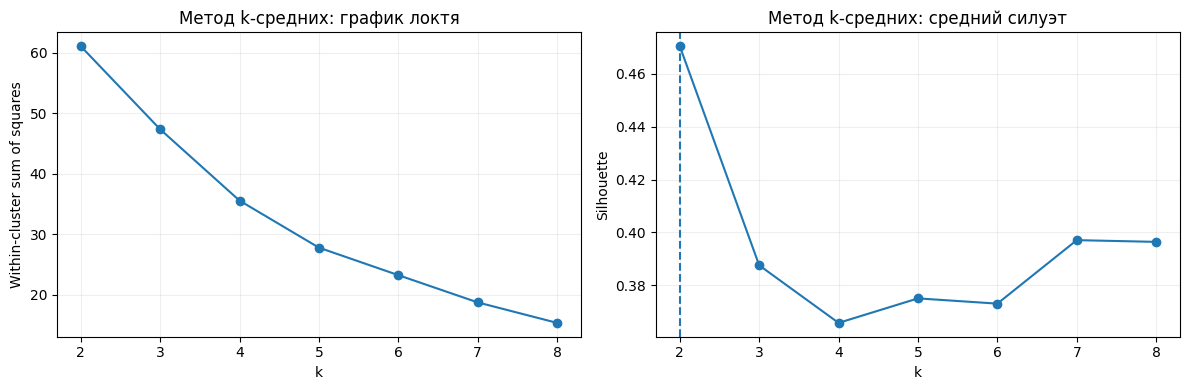

,Cities,Work,Price,Salary
KMeans,,,,
1,25,1789.24,84.97,59.03
2,21,1987.86,52.40,16.35


Кластер 1 (25 городов): Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los Angeles, Luxembourg, Madrid, Milan, Montreal, New York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich
Кластер 2 (21 городов): Athens, Bogota, Bombay, Buenos Aires, Caracas, Hong Kong, Johannesburg, Kuala Lumpur, Lagos, Lisbon, Manila, Mexico City, Nairobi, Nicosia, Panama, Rio de Janeiro, San Paulo, Seoul, Singpore, Taipei, Tel Aviv


,City,Work,Price,Salary,KMeans
0,Amsterdam,1714.0,65.6,49.0,1
1,Brussels,1708.0,73.8,50.5,1
2,Chicago,1924.0,73.9,61.9,1
3,Copenhagen,1717.0,91.3,62.9,1
4,Dublin,1759.0,76.0,41.4,1
5,Dusseldorf,1693.0,78.5,60.2,1
6,Frankfurt,1650.0,74.5,60.4,1
7,Geneva,1880.0,95.9,90.3,1
8,Helsinki,1667.0,113.6,66.6,1
9,Houston,1978.0,71.9,46.3,1


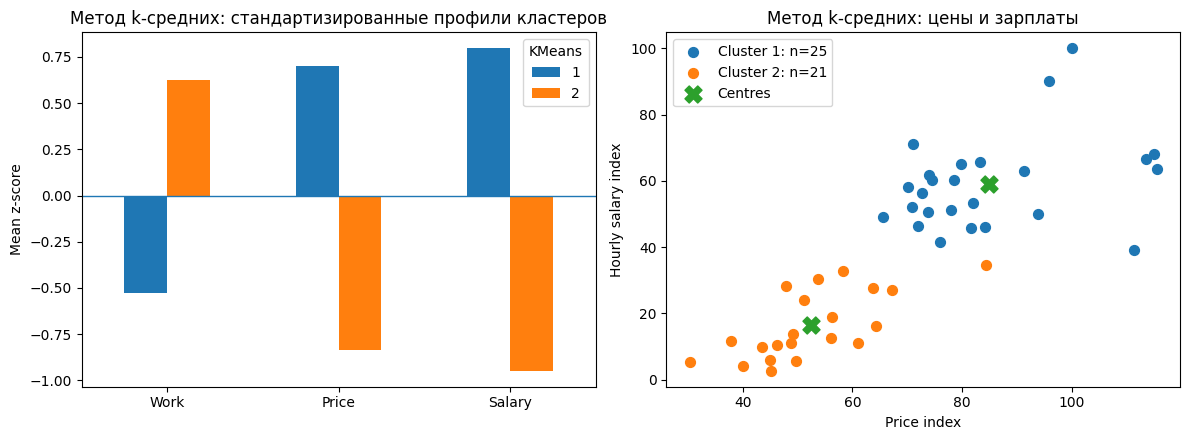

In [2]:
# Сопоставляем графики инерции и силуэта, затем показываем размеры, состав и профили групп.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(km_scores.k, km_scores.inertia, 'o-')
axes[0].set(title='Метод k-средних: график локтя', xlabel='k', ylabel='Within-cluster sum of squares', xticks=km_scores.k)
axes[1].plot(km_scores.k, km_scores.silhouette, 'o-')
axes[1].axvline(km_k, linestyle='--')
axes[1].set(title='Метод k-средних: средний силуэт', xlabel='k', ylabel='Silhouette', xticks=km_scores.k)
for ax in axes: ax.grid(alpha=.2)
plt.tight_layout(); plt.show()
km_summary = cities2.groupby('KMeans').agg(
    Cities=('City','size'), Work=('Work','mean'), Price=('Price','mean'), Salary=('Salary','mean'))
display(km_summary.round(2))
for c, part in cities2.groupby('KMeans'):
    print(f'Кластер {c} ({len(part)} городов):', ', '.join(part.City.str.replace('_', ' ').sort_values()))
display(cities2.sort_values(['KMeans','City']).reset_index(drop=True))

# Центры показаны в исходных единицах; двумерный график не заменяет трёхмерную модель.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
zprof2 = pd.DataFrame(X2, columns=features2).assign(KMeans=km_labels).groupby('KMeans').mean()
zprof2.T.plot.bar(ax=axes[0], rot=0)
axes[0].axhline(0, linewidth=1)
axes[0].set(title='Метод k-средних: стандартизированные профили кластеров', ylabel='Mean z-score')
for c, part in cities2.groupby('KMeans'):
    axes[1].scatter(part.Price, part.Salary, s=50, label=f'Cluster {c}: n={len(part)}')
centres2 = scaler2.inverse_transform(km_model.cluster_centers_)
axes[1].scatter(centres2[:,1], centres2[:,2], marker='X', s=150, label='Centres')
axes[1].set(title='Метод k-средних: цены и зарплаты', xlabel='Price index', ylabel='Hourly salary index')
axes[1].legend(); plt.tight_layout(); plt.show()
# Правый график показывает только два из трёх признаков модели.


### Интерпретация, проверка и вывод

Выбран **k = 2**: средний силуэт **0,4705**. Кластеры содержат **25 и 21 город** и полностью совпадают с двухкластерным решением Ward из первой работы. Номера переупорядочены по средней зарплате для удобства сравнения.

| Группа | n | Work, среднее | Price, среднее | Salary, среднее | Смысл |
|---|---:|---:|---:|---:|---|
| 1 | 25 | 1789,24 | 84,97 | 59,03 | Более высокие цены и зарплаты, меньшее рабочее время |
| 2 | 21 | 1987,86 | 52,40 | 16,35 | Более низкие цены и зарплаты, большее рабочее время |


In [3]:
# Сравниваем k-means с Ward на тех же стандартизированных наблюдениях.
ward2 = cut_tree(linkage(X2, method='ward'), n_clusters=2).ravel()
print('ARI k-means vs Ward:', adjusted_rand_score(km_labels, ward2))
# Проверяем выбранное k при 30 random_state и n_init=50.
# Это проверка зависимости от инициализации, а не от изменения данных.
km_repeats = []
for seed in range(30):
    repeat = KMeans(n_clusters=km_k, n_init=50, random_state=seed).fit(X2)
    km_repeats.append({'seed':seed, 'ARI':adjusted_rand_score(km_labels,repeat.labels_),
                       'inertia':repeat.inertia_})
km_repeats = pd.DataFrame(km_repeats)
display(km_repeats[['ARI','inertia']].agg(['min','median','max']).round(4))
cities2.to_csv('lab2_kmeans_clusters.csv', index=False, encoding='utf-8-sig')
km_summary.to_csv('lab2_kmeans_profiles.csv', encoding='utf-8-sig')
km_scores.to_csv('lab2_kmeans_scores.csv', index=False, encoding='utf-8-sig')


ARI k-means vs Ward: 1.0


,ARI,inertia
min,1.0,61.1166
median,1.0,61.1166
max,1.0,61.1166
